<a href="https://colab.research.google.com/github/DevXanderCode/blind_spot_of_frontier_models/blob/main/mechanical_localization_pilot.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mechanical localization — first pilot

This is a technical scaffold, not a completed experiment or fellowship answer. You must run the model, inspect each output, decide how to expand the evaluation, and write your own interpretation. No predictions or research findings are prefilled.

The attached labels contain **7 targets from 1 photograph**. They are not seven independent scenes. They mainly use position and appearance; they do not yet test the proposed contrast between direct and component-relative descriptions.

**Before scoring:** review every human box and description. In the supplied overlay, box 1 appears to clip part of the bolt head at its right edge. Correct it in the labeling page, download the updated JSON, and replace the bundled JSON when prompted below. Tighten unnecessary margins consistently. Do not revise ground truth after looking at model outputs.

## Open in Colab
1. Upload this notebook at https://colab.research.google.com/ using **File → Upload notebook**.
2. Select **Runtime → Change runtime type → GPU**. Free GPU availability varies.
3. Run the cells in order. Upload `localization-pilot-inputs.zip` when asked.
4. If you corrected your labels, upload the new JSON in the optional replacement cell.
5. Complete your own observations in the last section and download the results.

## Model choice and limits
The default is [Qwen/Qwen3-VL-4B-Instruct](https://huggingface.co/Qwen/Qwen3-VL-4B-Instruct), an open-weight 4B-class vision-language model whose card specifically describes 2D grounding and spatial perception. It is a task-relevant small model, not a substitute for every larger frontier model and not claimed to be the newest available model. [Qwen3.5-4B](https://huggingface.co/Qwen/Qwen3.5-4B) is a newer candidate worth considering before the final experiment; switching architectures requires a corresponding loading implementation.

This pilot defaults to 4-bit loading to reduce GPU memory use. Report that choice: quantization can affect results. If you later compare with full precision, keep labels, prompts, and image processing fixed and report the runs separately. This notebook downloads the checkpoint but does not export its weights into the results archive.


In [7]:
# Install before importing transformers. If Colab requests a restart, restart and resume below.
%pip -q install "transformers==4.57.6" "accelerate>=1.10,<2" "bitsandbytes>=0.48,<1" "huggingface_hub>=0.34,<1" pillow matplotlib pandas


In [8]:
from pathlib import Path
import json, hashlib, zipfile, shutil, re, math, uuid, platform, subprocess, sys
from datetime import datetime, timezone
from google.colab import files
import torch
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pandas as pd

if not torch.cuda.is_available():
    raise RuntimeError("Select Runtime → Change runtime type → GPU, then reconnect.")
print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory (GiB):", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1))


GPU: Tesla T4
GPU memory (GiB): 14.6


## Load your images and annotations
Upload the provided inputs ZIP. The originals and credits are included. None of the boxes or descriptions will be sent to an external inference API; the selected model runs on your Colab GPU. Uploaded files are still stored in the Colab session.


In [9]:
ROOT = Path("/content/mechanical-pilot").resolve()
ROOT.mkdir(parents=True, exist_ok=True)
uploaded = files.upload()
zip_names = [name for name in uploaded if name.lower().endswith(".zip")]
if len(zip_names) != 1:
    raise ValueError("Upload exactly one localization-pilot-inputs.zip file.")
with zipfile.ZipFile(zip_names[0]) as archive:
    for item in archive.infolist():
        target = (ROOT / item.filename).resolve()
        if not target.is_relative_to(ROOT):
            raise ValueError("ZIP contains an unsafe path.")
    archive.extractall(ROOT)
LABEL_PATH = ROOT / "mechanical-ground-truth.json"
print("Input files loaded into", ROOT)


Saving localization-pilot-inputs.zip to localization-pilot-inputs (1).zip
Input files loaded into /content/mechanical-pilot


In [10]:
# Optional: set True to upload the corrected labels you exported from the labeling page.
REPLACE_LABELS = False
if REPLACE_LABELS:
    revised = files.upload()
    candidates = [name for name in revised if name.lower().endswith(".json")]
    if len(candidates) != 1:
        raise ValueError("Upload exactly one corrected ground-truth JSON.")
    LABEL_PATH.write_bytes(revised[candidates[0]])


Validated 7 targets from 1 photograph(s).


,target,description,box
0,1,this is a Long hex-head bolt standing vertically.,"[860, 575, 1149, 1800]"
1,2,this is a Large flat washer at the top center,"[1158, 608, 1461, 960]"
2,3,Short pan-head machine screw the smallest at t...,"[1930, 668, 2440, 911]"
3,4,Long pan-head machine screw at the right secon...,"[1622, 932, 2519, 1181]"
4,5,"Fully threaded hex bolt / tap bolt (right, thi...","[1604, 1224, 2595, 1499]"
5,6,"Medium hex-head bolt, partially threaded (righ...","[1400, 1562, 2721, 1843]"
6,7,"Threaded rod / all-thread (bottom, spanning th...","[91, 1889, 3170, 2068]"


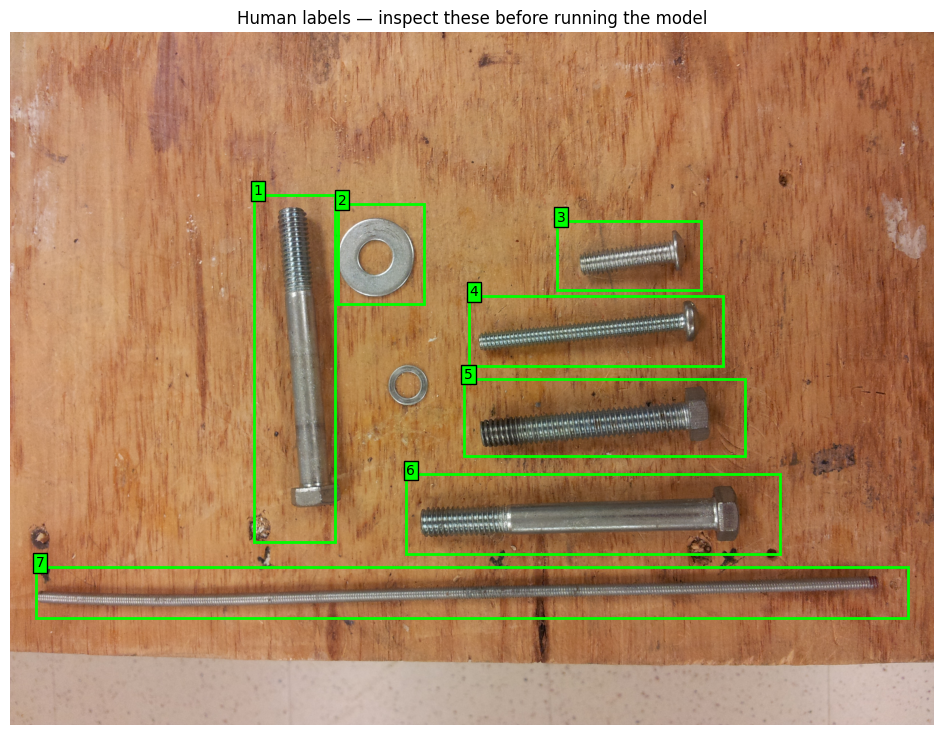

In [11]:
data = json.loads(LABEL_PATH.read_text())
assert data.get("coordinate_format") == "xyxy_pixels"
assert data.get("coordinate_origin") == "top_left"
annotations = data["annotations"]
assert annotations, "No annotations found."
seen = set()
for a in annotations:
    assert a["id"] not in seen, "Duplicate target ID"
    seen.add(a["id"])
    image_path = (ROOT / a["image_file"]).resolve()
    assert image_path.is_relative_to(ROOT)
    assert hashlib.sha256(image_path.read_bytes()).hexdigest() == a["image_sha256"]
    width, height = Image.open(image_path).size
    assert (width, height) == (a["image_width"], a["image_height"])
    box = a["bbox_xyxy"]
    assert len(box) == 4 and all(type(v) is int for v in box)
    assert 0 <= box[0] < box[2] <= width and 0 <= box[1] < box[3] <= height
    assert a["description"].strip()
print(f"Validated {len(annotations)} targets from {len({a['image_id'] for a in annotations})} photograph(s).")
display(pd.DataFrame([{"target": i+1, "description": a["description"], "box": a["bbox_xyxy"]} for i,a in enumerate(annotations)]))

for image_id in dict.fromkeys(a["image_id"] for a in annotations):
    group = [(i,a) for i,a in enumerate(annotations) if a["image_id"] == image_id]
    image = Image.open(ROOT / group[0][1]["image_file"])
    fig, ax = plt.subplots(figsize=(12, 9))
    ax.imshow(image)
    for i,a in group:
        x1,y1,x2,y2 = a["bbox_xyxy"]
        ax.add_patch(patches.Rectangle((x1,y1),x2-x1,y2-y1,fill=False,edgecolor="lime",linewidth=2))
        ax.text(x1,y1,str(i+1),color="black",bbox={"facecolor":"lime", "pad":2})
    ax.set_title("Human labels — inspect these before running the model")
    ax.axis("off")
    plt.show()


## Freeze your pilot settings
Set `LABELS_REVIEWED` to `True` only after you have inspected the boxes and descriptions. This is a record of your review, not evidence that the annotations are perfect.

The prompt requests **normalized 0–1000 coordinates**. We convert x using the image width and y using its height. We do not guess the scale of an answer. Malformed outputs are recorded separately and receive zero in the all-target localization score.

Images are resized proportionally to a maximum side of 1280 pixels before model preprocessing. This is an explicit pilot setting; small-object performance may depend on it. The model processor's image grid is also logged. Ground-truth boxes are never drawn on the model input or included in the prompt.


In [12]:
LABELS_REVIEWED = True  # Change after your own visual review.
assert LABELS_REVIEWED, "Review/correct the human annotations first, then set LABELS_REVIEWED=True."

MODEL_ID = "Qwen/Qwen3-VL-4B-Instruct"
REQUESTED_REVISION = "main"  # To reproduce a completed run, replace with its saved commit SHA.
USE_4BIT = True
MAX_SIDE = 1280
MAX_NEW_TOKENS = 128
SEED = 2026

RUN_DIR = ROOT / "results" / (datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid.uuid4().hex[:8])
RUN_DIR.mkdir(parents=True)
shutil.copyfile(LABEL_PATH, RUN_DIR / "ground_truth_used.json")


PosixPath('/content/mechanical-pilot/results/20261019T120835Z-672b8b85/ground_truth_used.json')

In [13]:
from huggingface_hub import HfApi
from transformers import AutoProcessor, Qwen3VLForConditionalGeneration, BitsAndBytesConfig, set_seed

set_seed(SEED)
model_info = HfApi().model_info(MODEL_ID, revision=REQUESTED_REVISION)
MODEL_REVISION = model_info.sha
compute_dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
load_kwargs = dict(revision=MODEL_REVISION, dtype=compute_dtype, device_map={"": 0}, attn_implementation="sdpa")
if USE_4BIT:
    load_kwargs["quantization_config"] = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=compute_dtype,
    )
processor = AutoProcessor.from_pretrained(MODEL_ID, revision=MODEL_REVISION)
model = Qwen3VLForConditionalGeneration.from_pretrained(MODEL_ID, **load_kwargs).eval()
print("Loaded:", MODEL_ID)
print("Exact revision:", MODEL_REVISION)
print("Precision:", "4-bit NF4 linear layers" if USE_4BIT else str(compute_dtype))

manifest = {
    "model_id": MODEL_ID, "model_revision": MODEL_REVISION,
    "four_bit": USE_4BIT, "compute_dtype": str(compute_dtype),
    "attention": "sdpa", "max_input_side": MAX_SIDE,
    "generation": {"do_sample": False, "max_new_tokens": MAX_NEW_TOKENS},
    "seed": SEED, "gpu": torch.cuda.get_device_name(0),
    "python": platform.python_version(), "torch": torch.__version__,
    "label_file_sha256": hashlib.sha256(LABEL_PATH.read_bytes()).hexdigest(),
    "labels_reviewed_by_user": LABELS_REVIEWED,
    "image_processor": processor.image_processor.to_dict(),
    "started_at_utc": datetime.now(timezone.utc).isoformat(),
    "limitations": ["Pilot; not a final benchmark", "Public photos may overlap training data", "No independent recognition test or relational contrast yet"],
}
(RUN_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2, default=str))
(RUN_DIR / "environment.txt").write_text(subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True))


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

...

model-00002-of-00002.safetensors:   0%|          | 0.00/3.91G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

Loaded: Qwen/Qwen3-VL-4B-Instruct
Exact revision: ebb281ec70b05090aa6165b016eac8ec08e71b17
Precision: 4-bit NF4 linear layers


14204

## Inference helpers
Greedy decoding is a fixed pilot choice rather than the model card's sampling recipe. It makes this small run easier to compare but does not establish robustness to alternative prompts or decoding settings. Format errors must not be silently relabeled as spatial errors.


In [14]:
def make_prompt(description):
    return (
        "Locate exactly one object described below in the image. "
        "Return a tight bounding box enclosing the entire visible target. "
        "Use normalized integer coordinates from 0 to 1000, with (0,0) at the top-left "
        "and (1000,1000) at the bottom-right of the whole image. "
        'Return only JSON in this exact structure: {"bbox_format":"xyxy_1000","bbox":[x1,y1,x2,y2]}. '
        'If the description does not identify a visible target, return {"bbox_format":"xyxy_1000","bbox":null}. '
        "Target description: " + description
    )

def parse_box(text):
    cleaned = text.strip()
    # Remove only a surrounding Markdown code fence; do not infer coordinates from prose.
    if cleaned.startswith("```") and cleaned.endswith("```"):
        cleaned = re.sub(r"^```(?:json)?\s*", "", cleaned, flags=re.IGNORECASE)
        cleaned = re.sub(r"\s*```$", "", cleaned)
    try:
        value = json.loads(cleaned)
    except (json.JSONDecodeError, ValueError):
        return None, "invalid_json"
    if not isinstance(value, dict) or value.get("bbox_format") != "xyxy_1000":
        return None, "invalid_format"
    box = value.get("bbox")
    if box is None:
        return None, "no_box"
    if not isinstance(box, list) or len(box) != 4 or any(type(v) is not int for v in box):
        return None, "invalid_coordinates"
    if not (0 <= box[0] < box[2] <= 1000 and 0 <= box[1] < box[3] <= 1000):
        return None, "invalid_coordinates"
    return box, "valid"

def to_pixels(box, width, height):
    if box is None:
        return None
    return [box[0]*width/1000, box[1]*height/1000, box[2]*width/1000, box[3]*height/1000]

def iou(a, b):
    if b is None:
        return 0.0
    intersection = max(0, min(a[2],b[2])-max(a[0],b[0])) * max(0, min(a[3],b[3])-max(a[1],b[1]))
    area_a = (a[2]-a[0])*(a[3]-a[1])
    area_b = (b[2]-b[0])*(b[3]-b[1])
    union = area_a + area_b - intersection
    return intersection / union if union > 0 else 0.0

@torch.inference_mode()
def predict(annotation):
    image = Image.open(ROOT / annotation["image_file"]).convert("RGB")
    image.thumbnail((MAX_SIDE, MAX_SIDE), Image.Resampling.LANCZOS)
    prompt = make_prompt(annotation["description"])
    messages = [{"role":"user", "content":[{"type":"image", "image":image}, {"type":"text", "text":prompt}]}]
    inputs = processor.apply_chat_template(messages, tokenize=True, add_generation_prompt=True, return_dict=True, return_tensors="pt")
    inputs.pop("token_type_ids", None)
    grid = inputs["image_grid_thw"].tolist() if "image_grid_thw" in inputs else None
    inputs = inputs.to(model.device)
    generated = model.generate(**inputs, do_sample=False, max_new_tokens=MAX_NEW_TOKENS)
    continuation = generated[:, inputs["input_ids"].shape[1]:]
    raw = processor.batch_decode(continuation, skip_special_tokens=True, clean_up_tokenization_spaces=False)[0]
    return {"prompt": prompt, "raw_output": raw, "submitted_image_size": list(image.size), "image_grid_thw": grid, "output_tokens": int(continuation.shape[1]), "reached_token_limit": int(continuation.shape[1]) >= MAX_NEW_TOKENS}


## Run the pilot yourself
This cell evaluates the currently loaded human labels. It writes each raw output immediately. Runtime failures stop the run and are logged as infrastructure errors, not counted as model mistakes. A fresh model prompt is used for every target; there is no conversation history carrying earlier answers.


In [15]:
if (RUN_DIR / "predictions.jsonl").exists():
    raise RuntimeError("This run already has predictions. Rerun the settings cell and model/manifest cell to create a separate run before repeating inference.")
rows = []
for index, annotation in enumerate(annotations, 1):
    try:
        prediction = predict(annotation)
    except Exception as error:
        (RUN_DIR / "runtime_error.json").write_text(json.dumps({"target_id": annotation["id"], "error": repr(error), "completed_targets": len(rows)}, indent=2))
        raise
    normalized, output_status = parse_box(prediction["raw_output"])
    pixel_box = to_pixels(normalized, annotation["image_width"], annotation["image_height"])
    score = iou(annotation["bbox_xyxy"], pixel_box)
    row = {"target_id": annotation["id"], "image_id": annotation["image_id"], "image_file": annotation["image_file"], "description": annotation["description"], "ground_truth_xyxy": annotation["bbox_xyxy"], **prediction, "status": output_status, "predicted_xyxy_1000": normalized, "predicted_xyxy_pixels": pixel_box, "iou": score, "iou_ge_0_5": score >= 0.5}
    rows.append(row)
    with (RUN_DIR / "predictions.jsonl").open("a") as stream:
        stream.write(json.dumps(row) + "\n")
    print(f"Target {index}/{len(annotations)} | {output_status} | IoU {score:.3f}")
    print(prediction["raw_output"])
    print()

# Both rates use ALL targets as denominator; malformed answers are not dropped.
summary = {
    "targets": len(rows), "independent_photographs": len({r["image_id"] for r in rows}),
    "mean_iou_all_targets": sum(r["iou"] for r in rows)/len(rows),
    "accuracy_iou_ge_0_5_all_targets": sum(r["iou_ge_0_5"] for r in rows)/len(rows),
    "valid_box_rate": sum(r["status"]=="valid" for r in rows)/len(rows),
    "format_error_count": sum(r["status"].startswith("invalid") for r in rows),
    "no_box_count": sum(r["status"]=="no_box" for r in rows),
}
(RUN_DIR / "summary.json").write_text(json.dumps(summary, indent=2))
display(pd.DataFrame(rows)[["description", "status", "iou", "iou_ge_0_5"]])
print(json.dumps(summary, indent=2))


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Target 1/7 | valid | IoU 0.556
{"bbox_format":"xyxy_1000","bbox": [291, 250, 360, 685]}

Target 2/7 | valid | IoU 0.728
{"bbox_format":"xyxy_1000","bbox":[355,265,438,382]}

Target 3/7 | valid | IoU 0.500
{"bbox_format":"xyxy_1000","bbox":[616, 285, 730, 353]}

Target 4/7 | valid | IoU 0.639
{"bbox_format":"xyxy_1000","bbox": [507, 387, 745, 462]}



Target 5/7 | valid | IoU 0.652
{"bbox_format":"xyxy_1000","bbox": [507, 511, 757, 600]}



Target 6/7 | valid | IoU 0.598
{"bbox_format":"xyxy_1000","bbox":[443, 653, 790, 733]}



Target 7/7 | valid | IoU 0.595
{"bbox_format":"xyxy_1000","bbox":[30,782,942,827]}



,description,status,iou,iou_ge_0_5
0,this is a Long hex-head bolt standing vertically.,valid,0.555589,True
1,this is a Large flat washer at the top center,valid,0.727512,True
2,Short pan-head machine screw the smallest at t...,valid,0.499803,False
3,Long pan-head machine screw at the right secon...,valid,0.638569,True
4,"Fully threaded hex bolt / tap bolt (right, thi...",valid,0.652357,True
5,"Medium hex-head bolt, partially threaded (righ...",valid,0.597547,True
6,"Threaded rod / all-thread (bottom, spanning th...",valid,0.594985,True


{
  "targets": 7,
  "independent_photographs": 1,
  "mean_iou_all_targets": 0.6094802988306277,
  "accuracy_iou_ge_0_5_all_targets": 0.8571428571428571,
  "valid_box_rate": 1.0,
  "format_error_count": 0,
  "no_box_count": 0
}


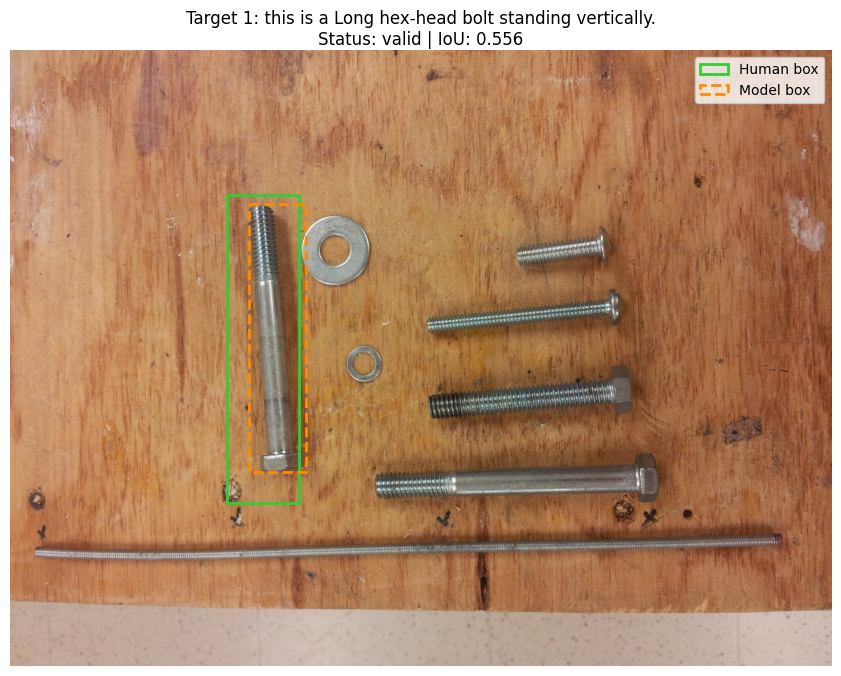

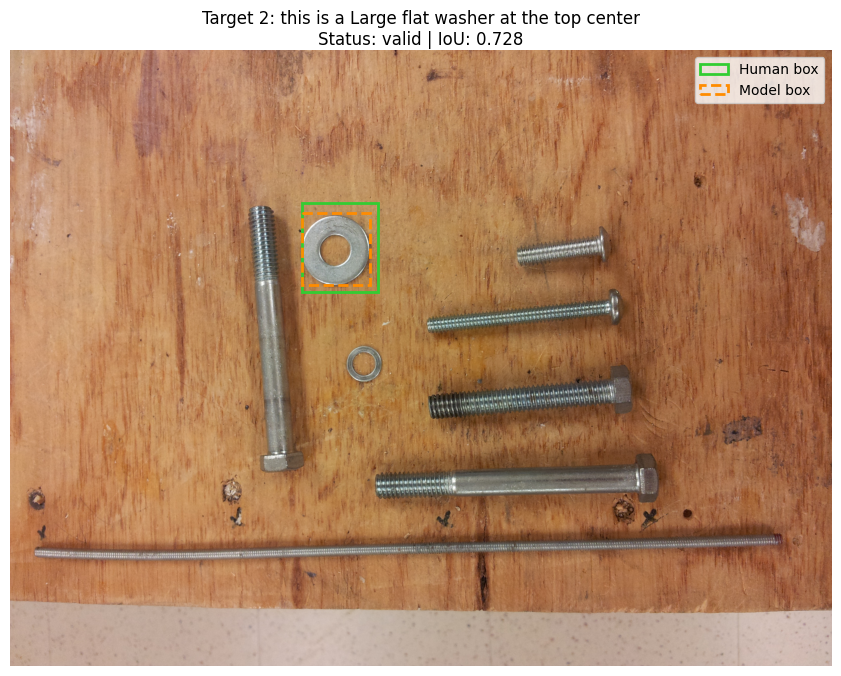

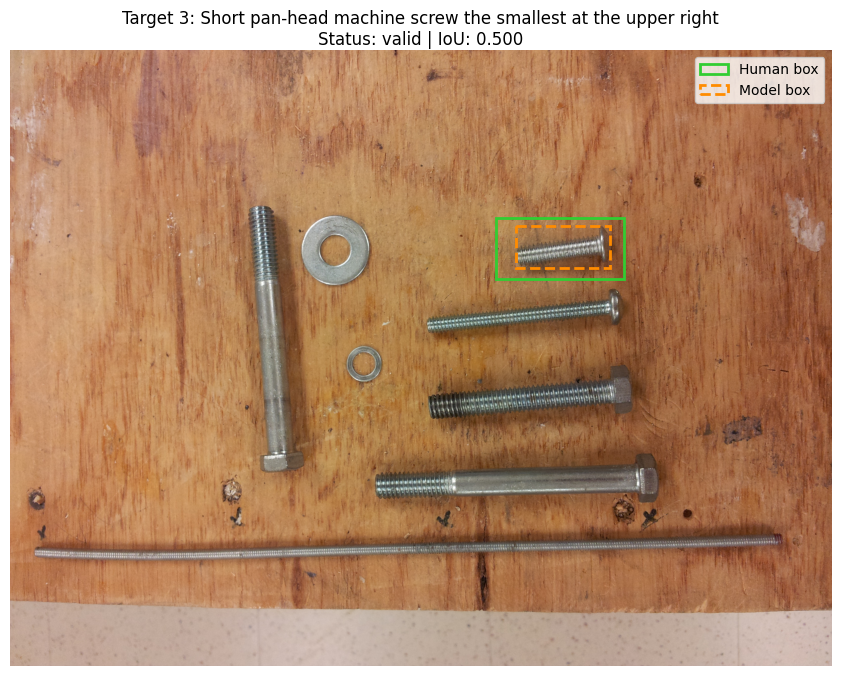

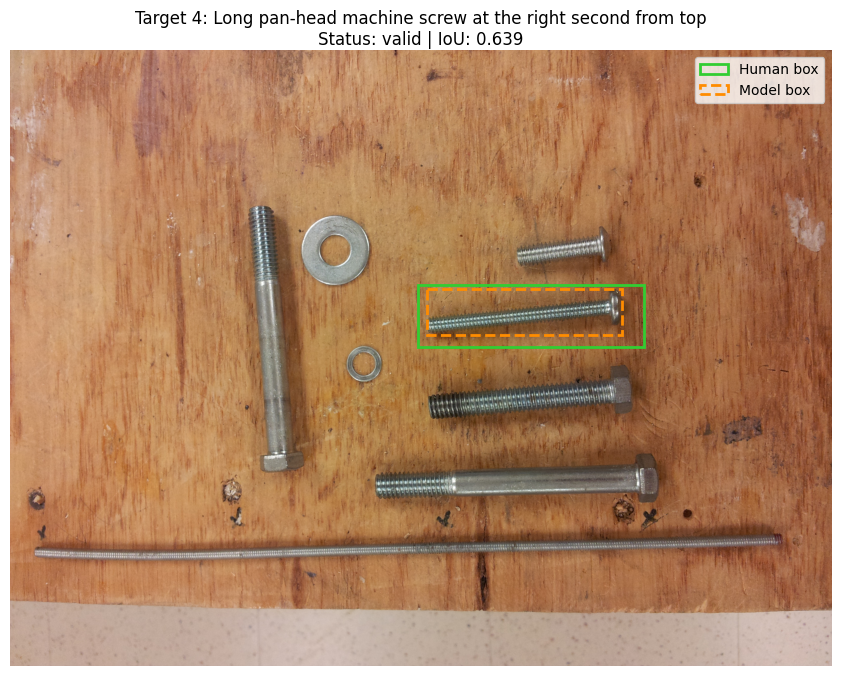

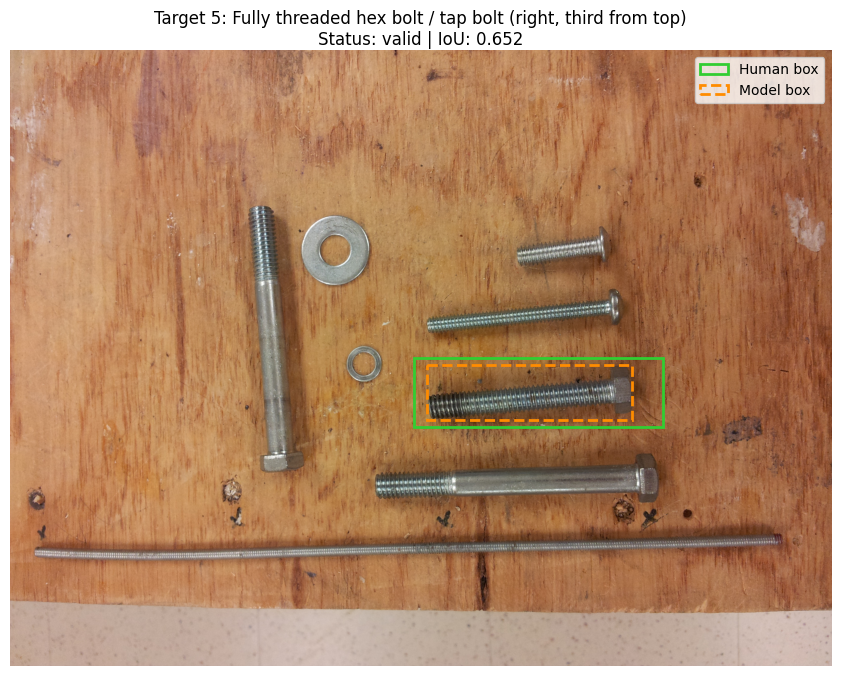

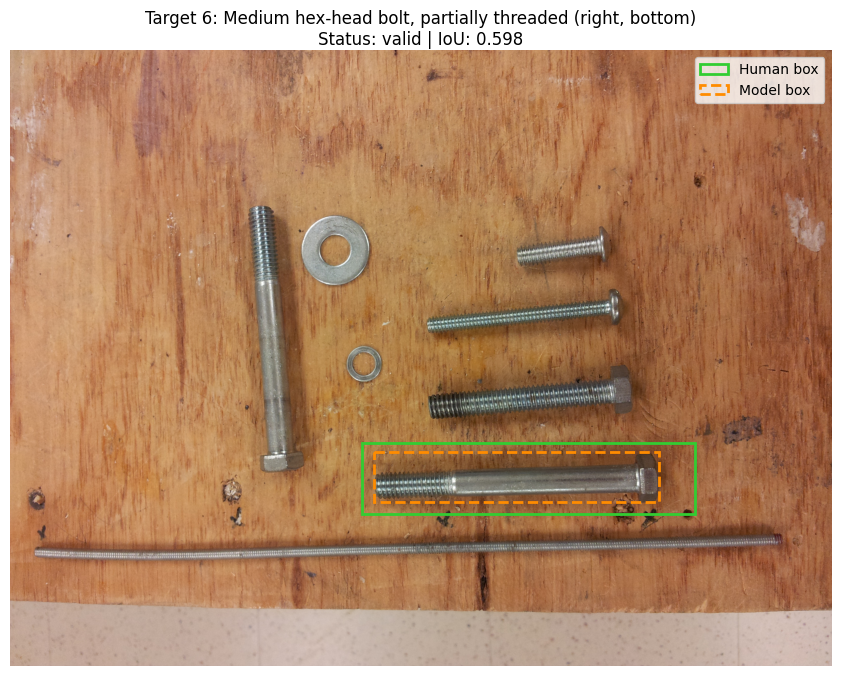

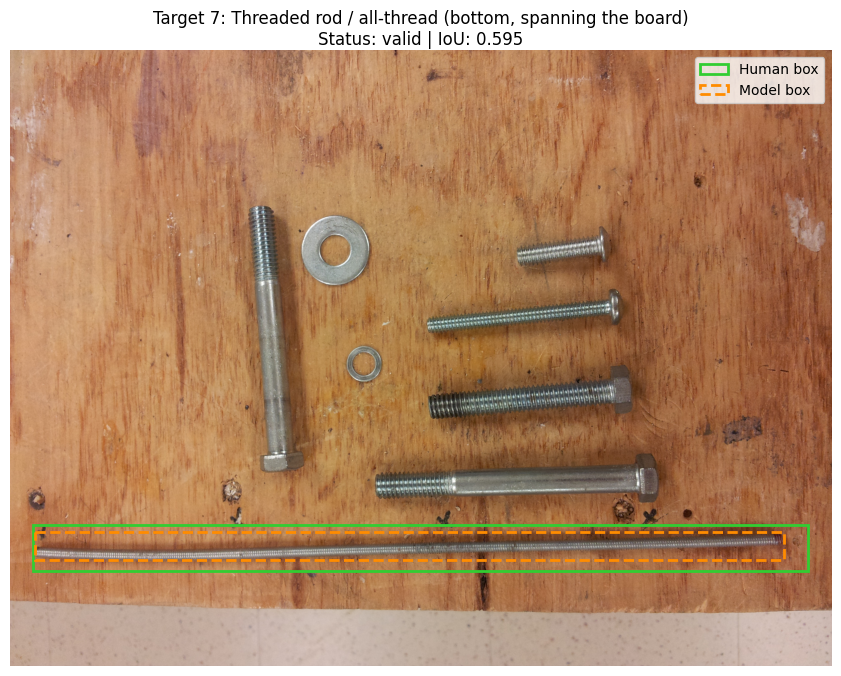

Complete human_review_to_complete.csv with your own observations. These fields are intentionally blank.


In [16]:
# Inspect every prediction, including successes. Green: your box. Orange dashed: model box.
(RUN_DIR / "overlays").mkdir(exist_ok=True)
for index, row in enumerate(rows, 1):
    fig, ax = plt.subplots(figsize=(11, 8))
    ax.imshow(Image.open(ROOT / row["image_file"]))
    for box,color,label,style in [(row["ground_truth_xyxy"],"limegreen","Human box","-"), (row["predicted_xyxy_pixels"],"darkorange","Model box","--")]:
        if box is not None:
            x1,y1,x2,y2 = box
            ax.add_patch(patches.Rectangle((x1,y1),x2-x1,y2-y1,fill=False,edgecolor=color,linewidth=2,linestyle=style,label=label))
    ax.set_title(f"Target {index}: {row['description']}\nStatus: {row['status']} | IoU: {row['iou']:.3f}", wrap=True)
    ax.legend()
    ax.axis("off")
    fig.savefig(RUN_DIR / "overlays" / f"target_{index:02d}.png", bbox_inches="tight", dpi=120)
    plt.show()
    plt.close(fig)

review = pd.DataFrame([{"target_id":r["target_id"], "description":r["description"], "correct_instance_selected":"", "failure_type":"", "my_observation":""} for r in rows])
review.to_csv(RUN_DIR / "human_review_to_complete.csv", index=False)
print("Complete human_review_to_complete.csv with your own observations. These fields are intentionally blank.")


## Your observations — write these yourself
- Did the model choose the intended object, even where the box was loose?
- Which issues were format errors, wrong-instance selections, or imprecise boundaries?
- Does the photograph actually support your technical names for the fasteners?
- What counterexample would weaken your hypothesis?
- What additional independently photographed scenes and matched direct/relational descriptions would test it?

Low box overlap alone does **not** prove failed recognition or relational reasoning. This pilot has no separate recognition measurement and no matched relational comparison. Do not draw those conclusions from it.

Any changes made after viewing these outputs are pilot exploration. Freeze a new protocol and use fresh held-out scenes for subsequent confirmatory claims. Keep alternate prompts, precision settings, and resolutions as distinct recorded runs rather than choosing whichever result best supports a story.

## Download and preserve
Download the results before ending the Colab session. Also save a copy of this notebook **with its outputs** from Colab. The archive below includes raw outputs, settings, the exact labels used, overlays, a blank human-review sheet, and sources. It does not include model weights or a completed fellowship README.


In [17]:
shutil.copytree(ROOT / "images", RUN_DIR / "images", dirs_exist_ok=True)
for name in ["CREDITS.md", "sources.json", "sources.csv"]:
    if (ROOT / name).exists():
        shutil.copyfile(ROOT / name, RUN_DIR / name)
archive_path = shutil.make_archive(str(RUN_DIR), "zip", root_dir=RUN_DIR)
files.download(archive_path)
print("Downloaded:", Path(archive_path).name)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: 20261019T120835Z-672b8b85.zip
